# 06 — Grad-CAM explanations (NeuroVision, Phase 6)
Final model: EfficientNet-B0. Target layer: `model.features[-1]` (last conv block, 7×7 feature map).
A heatmap shows what influenced the model's score. It is **not** evidence that the highlighted area is a tumor or that the prediction is correct.
GPU runtime recommended.

## 1. Setup: dataset (Kaggle) and final checkpoint (upload)

In [2]:
KAGGLE_DATASET = "sainibharat10/neurovision-brain-mri"
import os, io, glob, shutil, zipfile
DATA, ART = "/content/data", "/content/artifacts"
os.makedirs(ART, exist_ok=True); os.makedirs("ml", exist_ok=True)
!pip -q install kagglehub
import kagglehub

def find_root(p):
    hits = glob.glob(f"{p}/**/train", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

if not os.path.isdir(f"{DATA}/test"):
    try:
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception:
        kagglehub.login()
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    root = find_root(path)
    if root is None:
        for z in glob.glob(f"{path}/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        for z in glob.glob("/content/_raw/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        root = find_root("/content/_raw")
    assert root, "train/ folder not found"
    shutil.copytree(root, DATA, dirs_exist_ok=True)

CK = f"{ART}/best_model.pth"
if not os.path.exists(CK):
    from google.colab import files
    for name, data in files.upload().items():       # upload neurovision_final.zip (from notebook 05) or best_model.pth
        if name.endswith(".zip"): zipfile.ZipFile(io.BytesIO(data)).extractall(ART)
        elif name.endswith(".pth"): open(CK, "wb").write(data)
assert os.path.exists(CK), "best_model.pth not found"
print(sorted(os.listdir(DATA)), "| checkpoint OK")

100%|██████████| 107M/107M [00:00<00:00, 148MB/s]

Extracting files...


Saving neurovision_final.zip to neurovision_final.zip
['test', 'train', 'val'] | checkpoint OK


## 2. Grad-CAM module (`ml/explain.py`, reused by the backend later)

In [3]:
%%writefile ml/explain.py
"""Grad-CAM utilities for NeuroVision (shared by notebook 06 and the FastAPI backend).

Educational prototype. A heatmap shows which image regions influenced the model's score for a class;
it is NOT evidence that the highlighted area is a tumor or that the prediction is medically correct.
"""
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from matplotlib import colormaps

IMG_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


def preprocess(img: Image.Image, size: int = IMG_SIZE, mean=MEAN, std=STD) -> torch.Tensor:
    """PIL image -> (1, 3, size, size) normalized tensor. Identical to the training/eval pipeline."""
    a = np.asarray(img.convert("RGB").resize((size, size), Image.BILINEAR), dtype=np.float32) / 255.0
    t = torch.from_numpy(a).permute(2, 0, 1)
    t = (t - torch.tensor(mean).view(3, 1, 1)) / torch.tensor(std).view(3, 1, 1)
    return t.unsqueeze(0)


class GradCAM:
    """Grad-CAM (Selvaraju et al.) for a CNN classifier.

    target_layer: last convolutional block, e.g. model.features[-1] for EfficientNet-B0.
    """

    def __init__(self, model: torch.nn.Module, target_layer: torch.nn.Module):
        self.model = model.eval()
        self.acts = None
        self.grads = None
        self._handle = target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inputs, output):
        self.acts = output.detach()
        output.register_hook(lambda g: setattr(self, "grads", g.detach()))

    def remove(self):
        self._handle.remove()

    def __call__(self, x: torch.Tensor, class_idx=None):
        """x: (1, 3, H, W) normalized tensor on the model's device.
        class_idx=None explains the predicted class. Returns (cam[H, W] in [0, 1], probs[n_classes], class_idx)."""
        self.model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            x = x.detach().clone().requires_grad_(True)       # guarantees a graph even if params are frozen
            logits = self.model(x)
            probs = torch.softmax(logits, dim=1)[0].detach().cpu().numpy()
            idx = int(logits.argmax(dim=1)) if class_idx is None else int(class_idx)
            logits[0, idx].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)            # global-average-pooled gradients
        cam = F.relu((weights * self.acts).sum(dim=1, keepdim=True))   # weighted sum of feature maps
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.cpu().numpy().astype(np.float32), probs, idx


def heatmap_image(cam: np.ndarray, cmap: str = "jet") -> Image.Image:
    return Image.fromarray((colormaps[cmap](cam)[..., :3] * 255).astype(np.uint8))


def overlay(img: Image.Image, cam: np.ndarray, alpha: float = 0.45, cmap: str = "jet") -> Image.Image:
    """Blend the heatmap over the (resized) original image."""
    h, w = cam.shape
    base = np.asarray(img.convert("RGB").resize((w, h), Image.BILINEAR), dtype=np.float32)
    heat = np.asarray(heatmap_image(cam, cmap), dtype=np.float32)
    return Image.fromarray(((1 - alpha) * base + alpha * heat).clip(0, 255).astype(np.uint8))


def explain_image(model, gradcam: GradCAM, img: Image.Image, class_names, device, class_idx=None):
    """One-call helper for the API: returns predicted class, probabilities and Grad-CAM images."""
    x = preprocess(img).to(device)
    cam, probs, idx = gradcam(x, class_idx)
    return {
        "explained_class": class_names[idx],
        "predicted_class": class_names[int(np.argmax(probs))],
        "probabilities": {c: float(p) for c, p in zip(class_names, probs)},
        "cam": cam,
        "heatmap": heatmap_image(cam),
        "overlay": overlay(img, cam),
    }

Writing ml/explain.py


In [9]:
import ml.explain as E
def _fh(self, module, inputs, output):
    self.acts = output.detach()
    if output.requires_grad:
        output.register_hook(lambda g: setattr(self, "grads", g.detach()))
E.GradCAM._forward_hook = _fh
cam_engine.remove()
cam_engine = E.GradCAM(model, model.features[-1])

In [10]:
import os
os.makedirs("ml", exist_ok=True); open("ml/__init__.py", "a").close()
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image
from torchvision import models
from ml.explain import GradCAM, preprocess, overlay, heatmap_image, explain_image

device = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", device)
ck = torch.load(CK, map_location=device)
CLASSES = ck["classes"]

def build():
    m = models.efficientnet_b0(weights=None); m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(CLASSES)); return m
model = build(); model.load_state_dict(ck["model"]); model.to(device).eval()
cam_engine = GradCAM(model, model.features[-1])

rows = [(c, f"{DATA}/test/{c}/{f}") for c in CLASSES for f in sorted(os.listdir(f"{DATA}/test/{c}"))]
df = pd.DataFrame(rows, columns=["cls", "path"]); df["y"] = df.cls.map(CLASSES.index)
preds, confs = [], []
with torch.no_grad():
    for p in df.path:
        pr = torch.softmax(model(preprocess(Image.open(p)).to(device)), 1)[0]
        preds.append(int(pr.argmax())); confs.append(float(pr.max()))
df["pred"], df["conf"] = preds, confs
print(f"test accuracy (sanity, should be ~0.983): {(df.pred == df.y).mean():.4f}")

device: cpu
test accuracy (sanity, should be ~0.983): 0.9831


## 3. Examples: one correctly classified test image per class

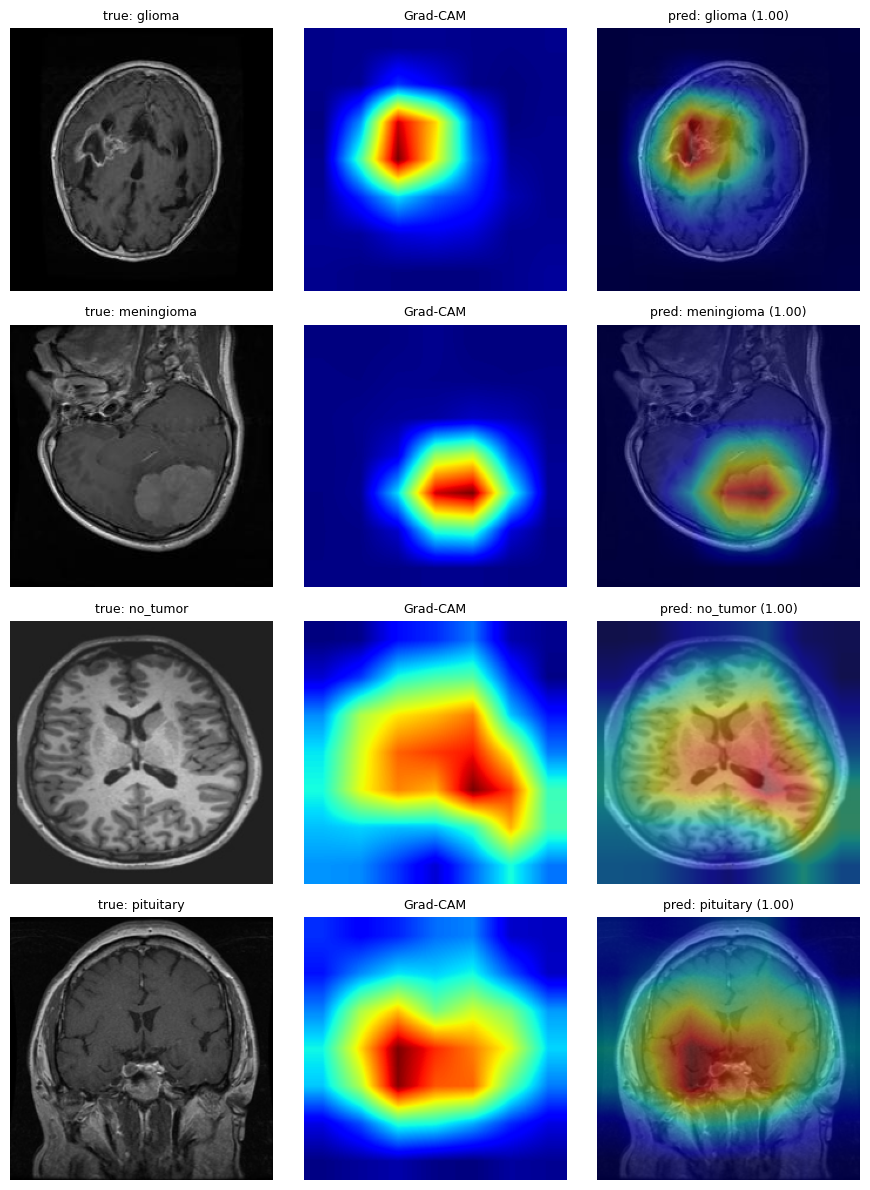

In [11]:
fig, ax = plt.subplots(len(CLASSES), 3, figsize=(9, 3 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    row = df[(df.cls == c) & (df.pred == df.y)].sort_values("conf", ascending=False).iloc[10]   # a typical confident one
    img = Image.open(row.path).convert("RGB")
    out = explain_image(model, cam_engine, img, CLASSES, device)
    assert out["explained_class"] == out["predicted_class"] == c
    for a, im, t in zip(ax[r], [img.resize((224, 224)), out["heatmap"], out["overlay"]],
                        [f"true: {c}", "Grad-CAM", f"pred: {out['predicted_class']} ({row.conf:.2f})"]):
        a.imshow(im); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(f"{ART}/gradcam_examples.png", dpi=130); plt.show()

## 4. Misclassified test images: why did it say that?
For each error: overlay for the **predicted** class vs the **true** class.

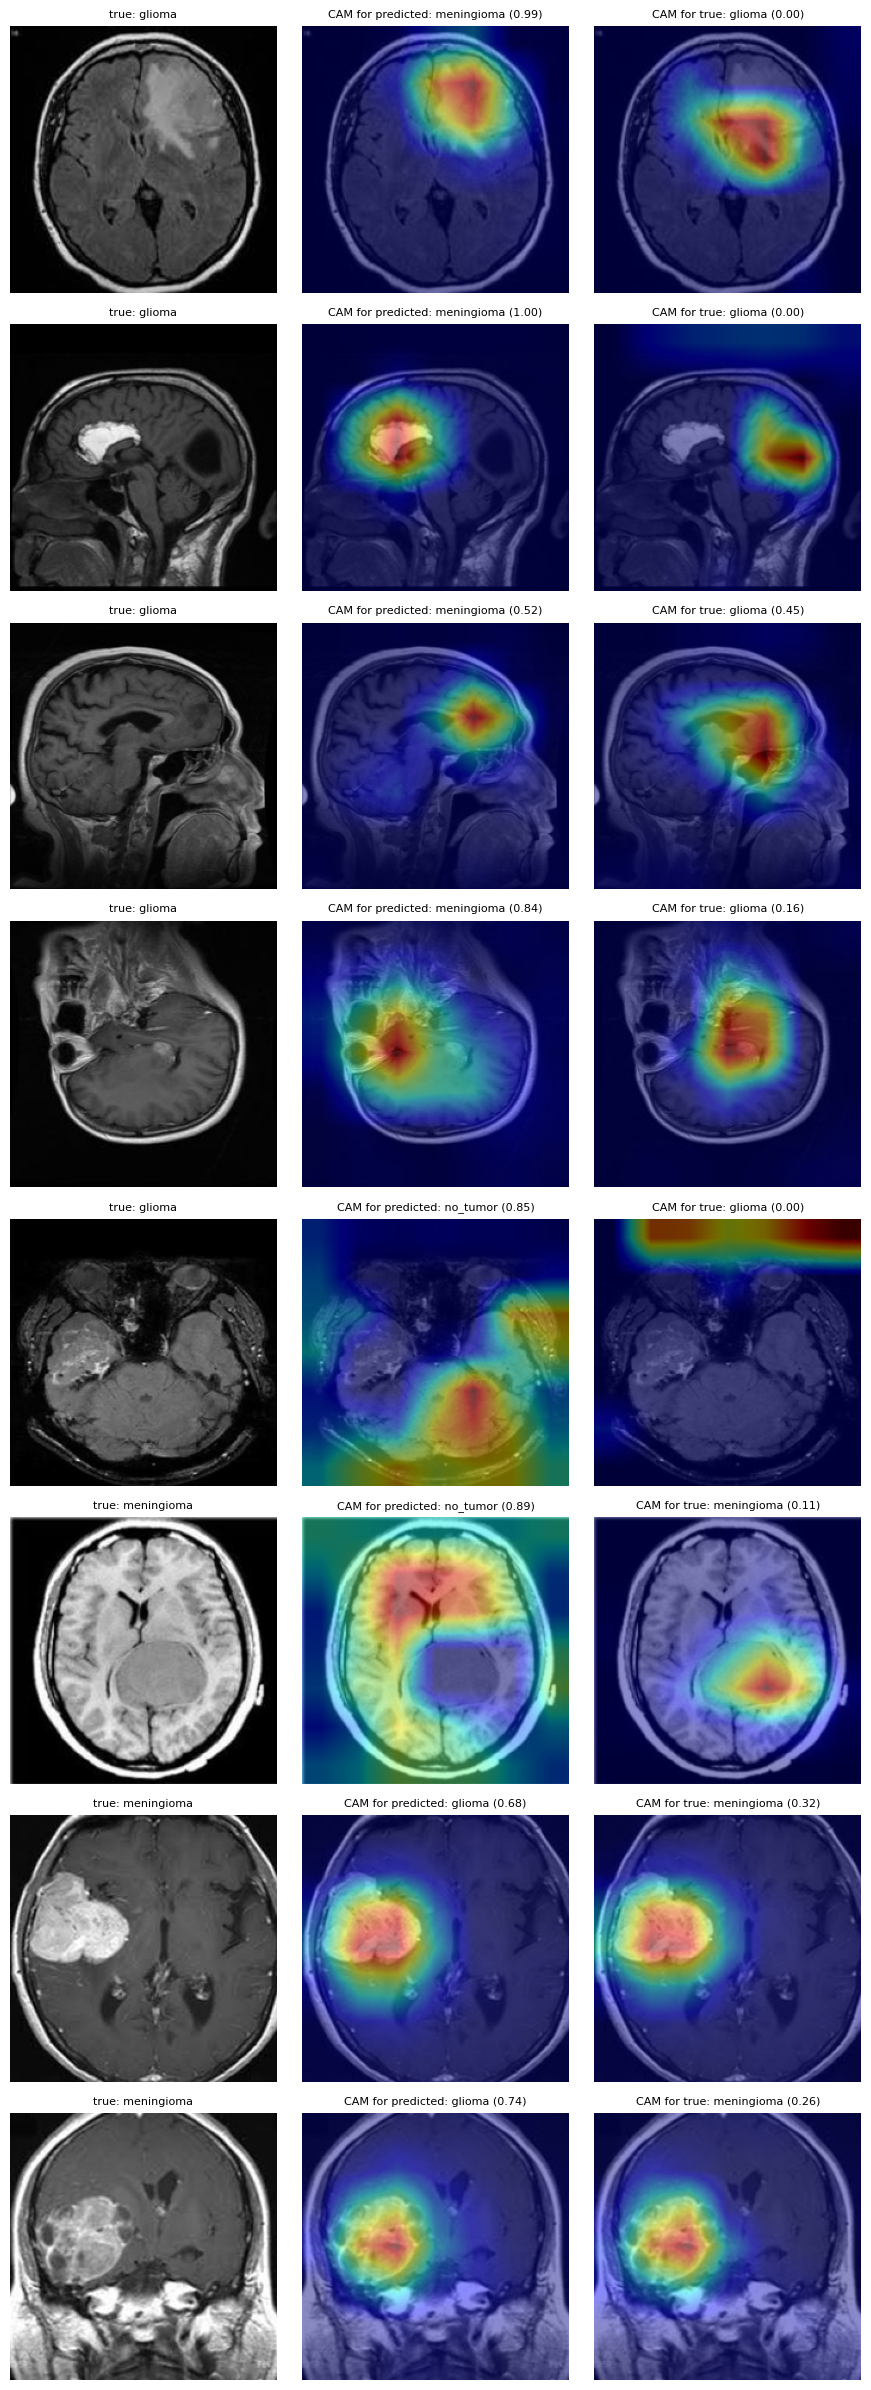

In [12]:
wrong = df[df.pred != df.y].reset_index(drop=True)
k = min(len(wrong), 8)
fig, ax = plt.subplots(k, 3, figsize=(9, 3 * k))
for r in range(k):
    row = wrong.iloc[r]; img = Image.open(row.path).convert("RGB")
    o_pred = explain_image(model, cam_engine, img, CLASSES, device)                       # predicted class
    o_true = explain_image(model, cam_engine, img, CLASSES, device, class_idx=row.y)      # true class
    for a, im, t in zip(ax[r], [img.resize((224, 224)), o_pred["overlay"], o_true["overlay"]],
                        [f"true: {CLASSES[row.y]}", f"CAM for predicted: {CLASSES[row.pred]} ({row.conf:.2f})",
                         f"CAM for true: {CLASSES[row.y]} ({o_true['probabilities'][CLASSES[row.y]]:.2f})"]):
        a.imshow(im); a.set_title(t, fontsize=8); a.axis("off")
plt.tight_layout(); plt.savefig(f"{ART}/gradcam_errors.png", dpi=120); plt.show()

## 5. Sanity checks (do the heatmaps actually reflect the model?)
1. **Class sensitivity:** the map for the predicted class should differ from the map for another class.
2. **Model randomization** (Adebayo et al.): a randomly initialized network should give very different maps. A map that stays similar would be edge-detector-like, not model-dependent.
3. **Deletion test:** masking the top-20% CAM pixels should lower the predicted-class probability more than masking 20% random pixels.

In [13]:
rng = np.random.default_rng(0)
sample = df.iloc[rng.choice(len(df), 100, replace=False)]
def corr(a, b):
    a, b = a.ravel(), b.ravel()
    return np.nan if a.std() < 1e-8 or b.std() < 1e-8 else float(np.corrcoef(a, b)[0, 1])

torch.manual_seed(0)
rand = build().to(device).eval(); rand_engine = GradCAM(rand, rand.features[-1])

c_class, c_rand, drop_cam, drop_rand = [], [], [], []
for p in sample.path:
    x = preprocess(Image.open(p)).to(device)
    cam, probs, idx = cam_engine(x)
    other = int([i for i in np.argsort(probs)[::-1] if i != idx][0])      # runner-up class
    cam_o, _, _ = cam_engine(x, other)
    c_class.append(corr(cam, cam_o))
    cam_r, _, _ = rand_engine(x, idx)
    c_rand.append(corr(cam, cam_r))
    with torch.no_grad():
        base = torch.softmax(model(x), 1)[0, idx].item()
        m_cam = torch.from_numpy(cam >= np.quantile(cam, 0.8)).to(device)
        m_rnd = torch.from_numpy(rng.random(cam.shape) >= 0.8).to(device)
        xc, xr = x.clone(), x.clone(); xc[:, :, m_cam] = 0; xr[:, :, m_rnd] = 0
        drop_cam.append(base - torch.softmax(model(xc), 1)[0, idx].item())
        drop_rand.append(base - torch.softmax(model(xr), 1)[0, idx].item())

sanity = {
    "corr_pred_class_vs_other_class_mean": float(np.nanmean(c_class)),
    "corr_trained_vs_random_model_mean": float(np.nanmean(c_rand)),
    "prob_drop_mask_top20pct_cam_mean": float(np.mean(drop_cam)),
    "prob_drop_mask_random20pct_mean": float(np.mean(drop_rand)),
    "n_images": len(sample),
}
print(json.dumps(sanity, indent=2))
print("\nExpect: class-sensitivity corr well below 1; trained-vs-random corr near 0; CAM-masking drop > random-masking drop.")
json.dump(sanity, open(f"{ART}/gradcam_sanity.json", "w"), indent=2)

{
  "corr_pred_class_vs_other_class_mean": -0.1285746143915161,
  "corr_trained_vs_random_model_mean": -0.0977492459004848,
  "prob_drop_mask_top20pct_cam_mean": 0.5210561508262254,
  "prob_drop_mask_random20pct_mean": 0.7202886119947278,
  "n_images": 100
}

Expect: class-sensitivity corr well below 1; trained-vs-random corr near 0; CAM-masking drop > random-masking drop.


## 6. Save and download

In [14]:
from google.colab import files
cam_engine.remove(); rand_engine.remove()
with zipfile.ZipFile("/content/neurovision_gradcam.zip", "w") as z:
    z.write("ml/explain.py", "ml/explain.py")
    for n in ["gradcam_examples.png", "gradcam_errors.png", "gradcam_sanity.json"]:
        z.write(f"{ART}/{n}", n)
files.download("/content/neurovision_gradcam.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes to fill in
- Do the heatmaps sit on the lesion/brain tissue, or on edges, skull or background?
- For errors, does the CAM for the true class look different from the predicted-class CAM?
- Sanity-check results and what they mean for how much to trust the explanations: